<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/13-evaluating-classifiers/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Who Should the Bank Call?

Between May 2008 and November 2010, a Portuguese bank ran a series of telephone marketing campaigns, calling customers to offer a **term deposit** (a savings account where the money stays locked in for a fixed period, in return for a higher interest rate). Researchers Sérgio Moro, Paulo Cortez and Paulo Rita published the records of 41,188 of those calls: who was called, some details about the customer and the call, the state of the economy at the time, and whether the customer said yes.

Phone calls cost money and annoy people who aren't interested. The goal of this project is to score customers so the bank can call the ones most likely to say yes, and to **evaluate that model the way the bank would need it evaluated**: not "how accurate is it", but "how much better are our calls, and can we trust it next year?" Along the way:

1. **Audit** the data, and find a feature that makes the problem look much easier than it is
2. **Split** the data and see why accuracy is useless here
3. **Compare** two models by ranking: ROC, precision-recall and gains curves
4. **Check calibration**, and see what class weighting does to it
5. Turn the scores into **decisions** that maximise profit
6. **Test** once, with honest intervals, and break the results down by group
7. Ask the hardest question: **does it work on the future?**

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/13-evaluating-classifiers/data/bank_marketing.csv.gz"
local = Path("data/bank_marketing.csv.gz")
bank = pd.read_csv(local if local.exists() else DATA_URL)
print(bank.shape)
bank.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

Each row is one call. The columns fall into four groups:

| group | columns |
|---|---|
| the customer | `age`, `job`, `marital`, `education`, `default` (has credit in default?), `housing` (has a housing loan?), `loan` (has a personal loan?) |
| this call | `contact` (mobile or landline), `month`, `day_of_week`, `duration` (seconds), `campaign` (number of calls to this customer in this campaign, including this one) |
| earlier campaigns | `pdays` (days since the customer was last contacted, 999 if never), `previous` (number of earlier contacts), `poutcome` (result of the previous campaign) |
| the economy | `emp.var.rate` (employment variation rate), `cons.price.idx` (consumer price index), `cons.conf.idx` (consumer confidence), `euribor3m` (the 3-month Euribor interest rate), `nr.employed` (number of employees, in thousands) |

The target is `y`: did the customer subscribe?

## 1. Audit

### The base rate

In [3]:
bank["subscribed"] = (bank["y"] == "yes").astype(int)
base_rate = bank["subscribed"].mean()
print(f"calls: {len(bank):,}   subscribed: {bank['subscribed'].sum():,}   base rate: {base_rate:.1%}")

calls: 41,188   subscribed: 4,640   base rate: 11.3%


About 1 call in 9 ends in a subscription. That number frames everything else: a model that predicts "no" for everyone is right about 89% of the time.

### A feature from the future: `duration`

`duration` is the length of the call in seconds. It's a very strong predictor: someone who stays on the phone for ten minutes is probably interested, and someone who hangs up after 20 seconds isn't. Watch what it does to a model's apparent quality:

In [4]:
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def logistic_on(numeric):
    return make_pipeline(
        make_column_transformer((OneHotEncoder(handle_unknown="ignore"), categorical), (StandardScaler(), numeric)),
        LogisticRegression(max_iter=3000))


economy = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
basic_numeric = ["age", "campaign", "pdays", "previous"] + economy
for name, numeric in [("without duration", basic_numeric), ("with duration", basic_numeric + ["duration"])]:
    auc = cross_val_score(logistic_on(numeric), bank, bank["subscribed"], cv=cv, scoring="roc_auc").mean()
    print(f"{name:<17} cross-validated AUC {auc:.3f}")

without duration  cross-validated AUC 0.791


with duration     cross-validated AUC 0.935


Adding `duration` makes the model look dramatically better. But think about **when** it's known: only **after** the call has ended, and by then you already know whether the customer said yes. The whole point of the model is to decide whom to call **before** calling. A model that needs the call's length is useless for that, however good its AUC.

This is **target leakage** (Module 11): a feature that wouldn't be available at the moment the prediction is made. The dataset's own documentation warns about it, and it's the most common mistake people make with this data: plenty of tutorials online report the leaked, impressive number. The test for leakage is always the same question: **at the moment I'd use this prediction, would I know this value?**

We drop `duration` for the rest of the project.

### Hidden missing values

`pdays` uses 999 to mean "never contacted before". As a number, that's nonsense: it tells a linear model that never-contacted customers were contacted a very long time ago. And several categorical columns contain the value `"unknown"`:

In [5]:
print(f"pdays = 999 (never contacted): {np.mean(bank['pdays'] == 999):.1%}")
print()
print((bank[categorical] == "unknown").mean().loc[lambda s: s > 0].round(3).to_string())

pdays = 999 (never contacted): 96.3%

job          0.008
marital      0.002
education    0.042
default      0.209
housing      0.024
loan         0.024


`pdays` is almost always 999, and the information it carries is mostly "was this customer contacted before?". We replace it with a yes/no column, `contacted_before`. (`previous` and `poutcome` already describe the earlier contacts.)

For the `"unknown"` values, the simplest honest choice is to keep `"unknown"` as a category of its own. Not knowing a customer's credit status might itself be informative, and one-hot encoding lets the model decide. Notice that `default` is almost never "yes" (3 customers), so it's really a known/unknown column.

### The rows are in time order

The dataset's documentation says the rows are ordered by date. There's no year column, but the months reveal it: whenever the month goes backwards (from December to March, say), a new year has started.

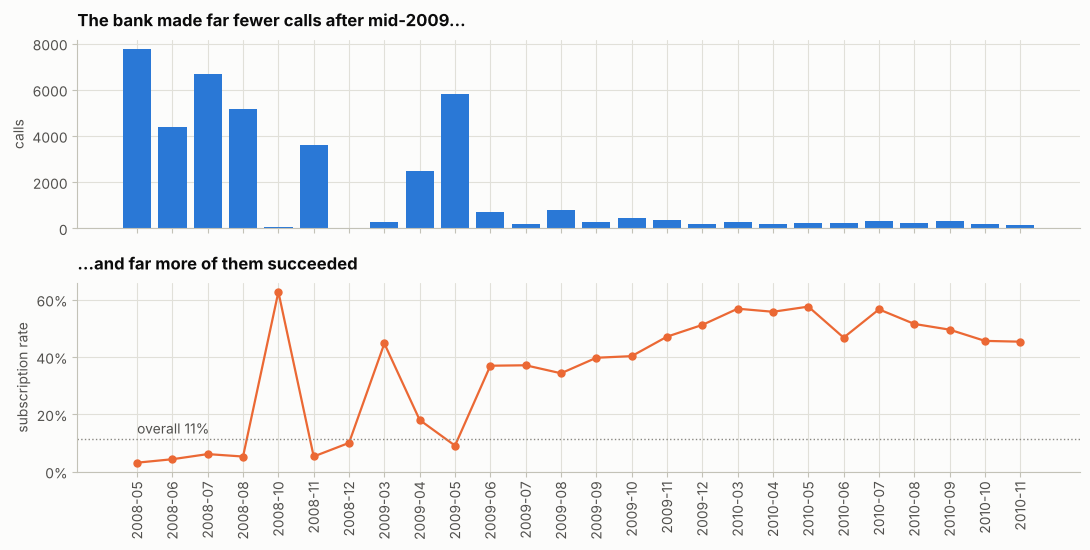

         calls   rate  euribor
period                        
2008-05   7763  0.031    4.858
2008-06   4374  0.043    4.932
2008-07   6685  0.061    4.962
2008-08   5175  0.052    4.965
2008-10     67  0.627    4.924
2008-11   3616  0.053    4.115
2008-12     10  0.100    3.493
2009-03    282  0.447    1.646
2009-04   2458  0.180    1.412
2009-05   5794  0.090    1.294
2009-06    715  0.369    1.258
2009-07    178  0.371    1.025


In [6]:
month_number = bank["month"].map({m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)})
bank["year"] = 2008 + (month_number.diff() < 0).cumsum()
bank["period"] = bank["year"].astype(str) + "-" + month_number.astype(str).str.zfill(2)

by_period = bank.groupby("period").agg(calls=("subscribed", "size"), rate=("subscribed", "mean"),
                                       euribor=("euribor3m", "mean"))
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].bar(range(len(by_period)), by_period["calls"], color=PALETTE[0], width=0.8)
axes[0].set_ylabel("calls")
axes[0].set_title("The bank made far fewer calls after mid-2009...")
axes[1].plot(range(len(by_period)), by_period["rate"], color=PALETTE[1], marker="o", markersize=5)
axes[1].axhline(base_rate, color=MUTED, linestyle=":", linewidth=1)
axes[1].text(0, base_rate + 0.02, f"overall {base_rate:.0%}", color=INK_2)
axes[1].set_ylabel("subscription rate")
axes[1].set_ylim(0, None)
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[1].set_title("...and far more of them succeeded")
axes[1].set_xticks(range(len(by_period)), by_period.index, rotation=90)
fig.tight_layout()
plt.show()
print(by_period.round(3).head(12).to_string())

This changes how we should think about the whole project:

- In 2008, the bank made thousands of calls a month and about 1 in 20 succeeded. (The spikes in October and December 2008 are months with only a few dozen calls.)
- From mid-2009, the number of calls dropped to a few hundred a month, and **40 to 60%** succeeded.
- At the same time, the economy changed: the Euribor interest rate fell from about 5% to under 1% during the financial crisis.

We can't tell from the data why the success rate jumped. The bank might have started choosing more carefully whom to call (perhaps using a model like ours), or customers might have valued safe savings more in a crisis, or both. Either way, the later calls come from a different world than the earlier ones. Section 7 comes back to this, because it decides whether the model is any use next year.

## 2. Split, and why accuracy is useless here

First, the features as decided above:

In [7]:
X = bank.drop(columns=["y", "subscribed", "duration", "year", "period"]).copy()
X["contacted_before"] = (X["pdays"] != 999).astype(int)
X = X.drop(columns="pdays")
y = bank["subscribed"].to_numpy()
numeric = [c for c in X.columns if c not in categorical]
print("numeric:    ", numeric)
print("categorical:", categorical)

numeric:     ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contacted_before']
categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


We follow the usual plan: hold out 20% as a test set, stratified so it has the same base rate, and make every decision with cross-validation on the other 80% (the development set). Section 7 then asks a different and harder question, with a split by time.

In [8]:
from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print(f"development: {len(X_dev):,} calls, {y_dev.mean():.1%} subscribed")
print(f"test:        {len(X_test):,} calls, {y_test.mean():.1%} subscribed")

development: 32,950 calls, 11.3% subscribed
test:        8,238 calls, 11.3% subscribed


Two models:

- **Logistic regression**, with one-hot encoded categories and standardised numbers.
- **Histogram gradient boosting** (`HistGradientBoostingClassifier`), a tree-based model that's often the strongest choice for tables like this one. Module 14 explains how it works; here we treat it as a model to evaluate. It handles categories natively once they're turned into integer codes.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import OrdinalEncoder


def make_logistic(**options):
    return make_pipeline(
        make_column_transformer((OneHotEncoder(handle_unknown="ignore"), categorical), (StandardScaler(), numeric)),
        LogisticRegression(max_iter=3000, **options))


def make_boosting():
    encode = make_column_transformer(
        (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
        ("passthrough", numeric))
    return make_pipeline(encode, HistGradientBoostingClassifier(
        categorical_features=list(range(len(categorical))), random_state=0))


models = {"logistic regression": make_logistic(), "gradient boosting": make_boosting()}
cv_probs = {name: cross_val_predict(model, X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
            for name, model in models.items()}

Start with accuracy, at the default threshold of 0.5, next to the "always no" baseline:

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

print(f"{'always no':<20} accuracy {1 - y_dev.mean():.3f}")
for name, p in cv_probs.items():
    pred = p >= 0.5
    print(f"{name:<20} accuracy {accuracy_score(y_dev, pred):.3f}   recall {recall_score(y_dev, pred):.3f}   precision {precision_score(y_dev, pred):.3f}")

always no            accuracy 0.887
logistic regression  accuracy 0.900   recall 0.230   precision 0.660
gradient boosting    accuracy 0.901   recall 0.257   precision 0.658


Both models beat "always no" by about one percentage point of accuracy. Taken at face value, that's a pathetic improvement. But accuracy is the wrong question. At a threshold of 0.5, the models only flag customers they think are more likely than not to subscribe, which finds about a quarter of the subscribers.

The bank's real question is different: **if we call the customers the model ranks highest, how many subscribers do we reach, and is it worth the cost of the calls?** That's a question about **ranking** and **costs**, so those are the tools to use.

## 3. Compare the models by ranking

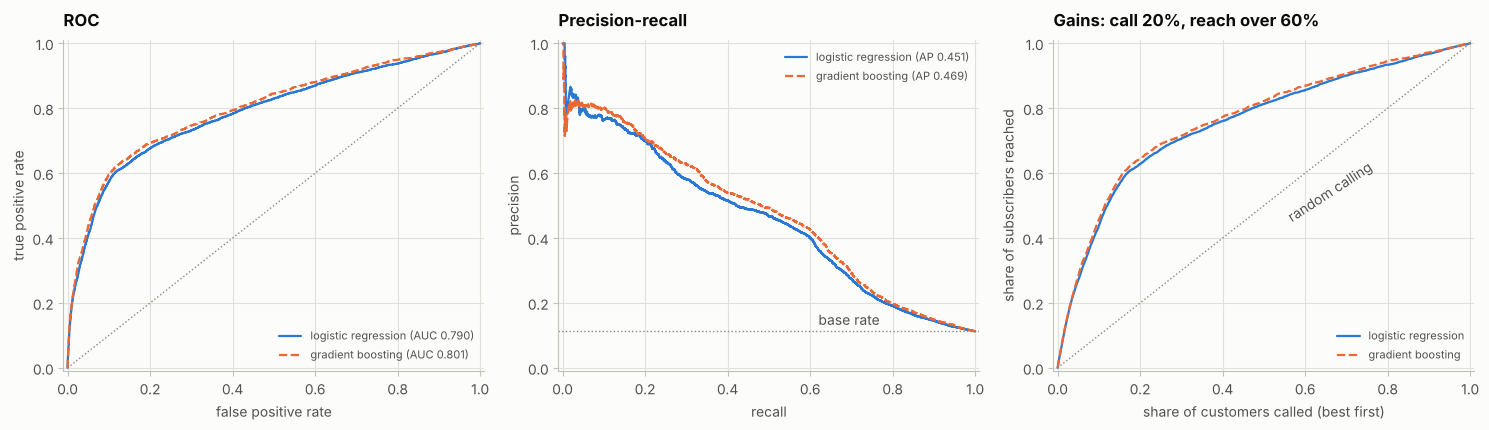

In [11]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
styles = {"logistic regression": (PALETTE[0], "-"), "gradient boosting": (PALETTE[1], "--")}
for name, p in cv_probs.items():
    colour, style = styles[name]
    fpr, tpr, _ = roc_curve(y_dev, p)
    axes[0].plot(fpr, tpr, color=colour, linestyle=style, label=f"{name} (AUC {roc_auc_score(y_dev, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_dev, p)
    axes[1].plot(rec, prec, color=colour, linestyle=style, label=f"{name} (AP {average_precision_score(y_dev, p):.3f})")
    order = np.argsort(-p)
    share_called = np.arange(1, len(p) + 1) / len(p)
    share_reached = np.cumsum(y_dev[order]) / y_dev.sum()
    axes[2].plot(share_called, share_reached, color=colour, linestyle=style, label=name)
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC")
axes[1].axhline(y_dev.mean(), color=MUTED, linestyle=":", linewidth=1)
axes[1].text(0.62, y_dev.mean() + 0.02, "base rate", color=INK_2)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall")
axes[2].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
axes[2].text(0.55, 0.45, "random calling", color=INK_2, rotation=33)
axes[2].set_xlabel("share of customers called (best first)")
axes[2].set_ylabel("share of subscribers reached")
axes[2].set_title("Gains: call 20%, reach over 60%")
for ax in axes:
    ax.legend(loc="lower right" if ax is not axes[1] else "upper right", fontsize=8)
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
fig.tight_layout()
plt.show()

Three views of the same ranking:

- **ROC**: both models are well above the diagonal, with AUCs around 0.8. Gradient boosting is slightly ahead.
- **Precision-recall**: precision starts high (the very top-ranked customers subscribe more than half the time) and falls towards the base rate as you go down the list.
- The **gains chart** (also called a cumulative gains or lift chart) is the one a marketing team understands at once: sort customers by score, and plot the share of all subscribers reached against the share of customers called. Random calling gives the diagonal. The models' curves rise steeply at first: the best-scored customers are where the subscribers are.

A table of the same idea, for a few call budgets:

In [12]:
def top_k_summary(y_true, p, share):
    """Hit rate (precision at k) and share of subscribers reached when calling the top share by score."""
    top = np.argsort(-p)[:int(share * len(p))]
    return y_true[top].mean(), y_true[top].sum() / y_true.sum()


rows = {}
for share in [0.05, 0.10, 0.20, 0.30, 0.50]:
    hit_lr, reached_lr = top_k_summary(y_dev, cv_probs["logistic regression"], share)
    hit_gb, reached_gb = top_k_summary(y_dev, cv_probs["gradient boosting"], share)
    rows[f"top {share:.0%}"] = {"hit rate, logistic": hit_lr, "hit rate, boosting": hit_gb, "lift, boosting": hit_gb / y_dev.mean(),
                                "reached, logistic": reached_lr, "reached, boosting": reached_gb}
pd.DataFrame(rows).T.round(3)

,"hit rate, logistic","hit rate, boosting","lift, boosting","reached, logistic","reached, boosting"
top 5%,0.611,0.637,5.654,0.271,0.283
top 10%,0.493,0.514,4.564,0.438,0.456
top 20%,0.354,0.362,3.214,0.628,0.643
top 30%,0.265,0.269,2.384,0.706,0.715
top 50%,0.183,0.185,1.645,0.812,0.822


The **hit rate** is the share of called customers who subscribe (precision at k), and **reached** is the share of all subscribers among the customers called. **Lift** is the hit rate divided by the base rate: calling the top 5% of customers by score gives more than five times as many subscriptions per call as calling at random. Calling the top 20% reaches more than 60% of all the subscribers.

The two models are close at every budget, with gradient boosting a little ahead. Whether that small difference is real, we'll ask on the test set.

## 4. Check calibration

The profit calculation in the next section needs probabilities that mean what they say. Here are both models, plus a third: logistic regression with `class_weight="balanced"`, the common "fix" for imbalance from the lesson.

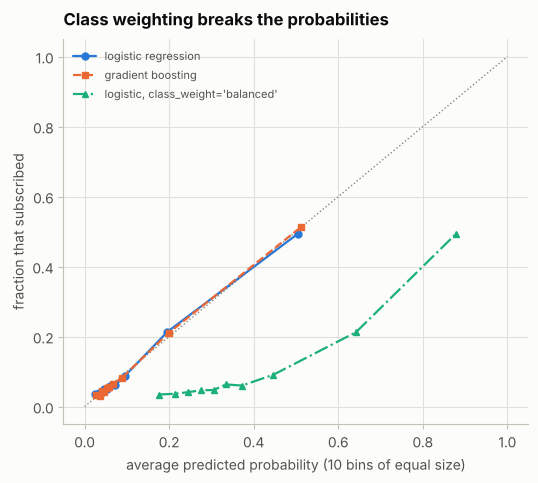

actual subscription rate: 0.113


,AUC,Brier,average prediction
logistic regression,0.7896,0.0784,0.1127
gradient boosting,0.8006,0.0766,0.1128
"logistic, class_weight='balanced'",0.7904,0.1635,0.3888
base rate for everyone,0.5000,0.1000,0.1127


In [13]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

cv_probs_weighted = cross_val_predict(make_logistic(class_weight="balanced"), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
all_probs = {**cv_probs, "logistic, class_weight='balanced'": cv_probs_weighted}

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
for (name, p), colour, marker, style in zip(all_probs.items(), PALETTE, ["o", "s", "^"], ["-", "--", "-."]):
    frac_pos, mean_pred = calibration_curve(y_dev, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, color=colour, marker=marker, markersize=5, linestyle=style, label=name)
ax.set_xlabel("average predicted probability (10 bins of equal size)")
ax.set_ylabel("fraction that subscribed")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Class weighting breaks the probabilities")
plt.show()

rows = {name: {"AUC": roc_auc_score(y_dev, p), "Brier": brier_score_loss(y_dev, p), "average prediction": p.mean()}
        for name, p in all_probs.items()}
rows["base rate for everyone"] = {"AUC": 0.5, "Brier": brier_score_loss(y_dev, np.full(len(y_dev), y_dev.mean())),
                                  "average prediction": y_dev.mean()}
print(f"actual subscription rate: {y_dev.mean():.3f}")
pd.DataFrame(rows).T.round(4)

With 89% of customers having low scores, equal-width bins would put almost everyone in the first two bins, so this plot uses `strategy="quantile"`: ten bins with the same number of customers each.

- **Both plain models are well calibrated**: their points follow the diagonal, and their average prediction matches the actual rate.
- **The class-weighted model has the same AUC**, so it ranks customers just as well. But its probabilities are far too high: when it says about 0.65, only about a fifth of those customers subscribe. Its average prediction is more than three times the real rate, and its Brier score is twice as bad as the others.

This is the lesson's warning in real data. Using the weighted model's probabilities in a profit calculation would mean calling far too many people. We continue with the two plain models.

## 5. Turn scores into decisions

The bank's true costs aren't public, so we'll use **illustrative numbers**, chosen to be plausible and easy to change:

- Each call costs **5 euros** (an agent's time, the phone system, and some goodwill lost by annoying people).
- Each subscription is worth **40 euros** to the bank (the margin it earns on the deposit).

Change them and rerun the notebook to see how the decisions change.

Each call is a bet: it costs 5 for certain and earns 40 with probability `p`. It's worth making when `40p > 5`, that is when `p > 5 / 40 = 0.125`. This is the lesson's cost formula, written with a gain instead of a cost. Note that it's above the base rate of 11%: calling **everyone** loses money on average.

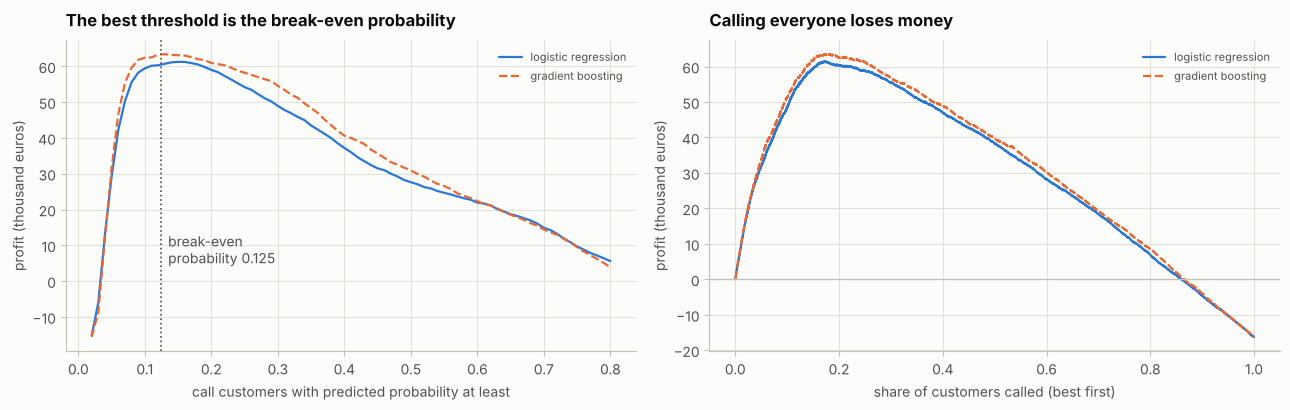

logistic regression  best threshold 0.15: profit  61,240   at 0.125:  60,445   calls 19.2% of customers
gradient boosting    best threshold 0.13: profit  63,385   at 0.125:  63,265   calls 18.2% of customers
call everyone        profit -16,270


In [14]:
COST_PER_CALL = 5
VALUE_PER_SUBSCRIPTION = 40
break_even = COST_PER_CALL / VALUE_PER_SUBSCRIPTION


def profit(y_true, call):
    """Total profit from calling the customers where call is True."""
    call = np.asarray(call, dtype=bool)
    return VALUE_PER_SUBSCRIPTION * np.sum(y_true[call]) - COST_PER_CALL * np.sum(call)


thresholds = np.round(np.arange(0.02, 0.81, 0.01), 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, p in cv_probs.items():
    colour, style = styles[name]
    axes[0].plot(thresholds, [profit(y_dev, p >= t) / 1000 for t in thresholds], color=colour, linestyle=style, label=name)
    order = np.argsort(-p)
    cumulative = np.cumsum(VALUE_PER_SUBSCRIPTION * y_dev[order] - COST_PER_CALL) / 1000
    axes[1].plot(np.arange(1, len(p) + 1) / len(p), cumulative, color=colour, linestyle=style, label=name)
axes[0].axvline(break_even, color=INK_2, linestyle=":", linewidth=1.2)
axes[0].text(break_even + 0.01, 5, f"break-even\nprobability {break_even}", color=INK_2)
axes[0].set_xlabel("call customers with predicted probability at least")
axes[0].set_ylabel("profit (thousand euros)")
axes[0].set_title("The best threshold is the break-even probability")
axes[1].axhline(0, color=AXIS, linewidth=1)
axes[1].set_xlabel("share of customers called (best first)")
axes[1].set_ylabel("profit (thousand euros)")
axes[1].set_title("Calling everyone loses money")
for ax in axes:
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

for name, p in cv_probs.items():
    best = thresholds[np.argmax([profit(y_dev, p >= t) for t in thresholds])]
    print(f"{name:<20} best threshold {best:.2f}: profit {profit(y_dev, p >= best):>7,}   "
          f"at {break_even}: {profit(y_dev, p >= break_even):>7,}   calls {np.mean(p >= break_even):.1%} of customers")
print(f"{'call everyone':<20} profit {profit(y_dev, np.ones(len(y_dev))):>7,}")

Both pictures tell the same story:

- On the left, profit rises as the threshold falls from high values (more good calls), peaks, then drops as the threshold falls below the break-even point (calls that cost more than they're expected to earn). The peak sits at or just above the break-even probability of 0.125, as the theory predicts for well-calibrated models, and the profit at exactly 0.125 is within about 1% of the best threshold found by searching.
- On the right, the same thing as a budget: calling the best-scored customers first, profit climbs until roughly 18% of customers have been called, then falls, and calling everyone ends in a loss.

So the decision rule is: **call customers whose predicted probability is at least 0.125**. We chose it from the costs, not by searching for the best threshold in the data, and cross-validation confirms it's a near-perfect choice. That means calling a little under one customer in five.

## 6. Test once

Everything so far used only the development set. Now we fit both models on all of it, and evaluate on the test set exactly once, with the rule fixed in advance: call if the probability is at least 0.125.

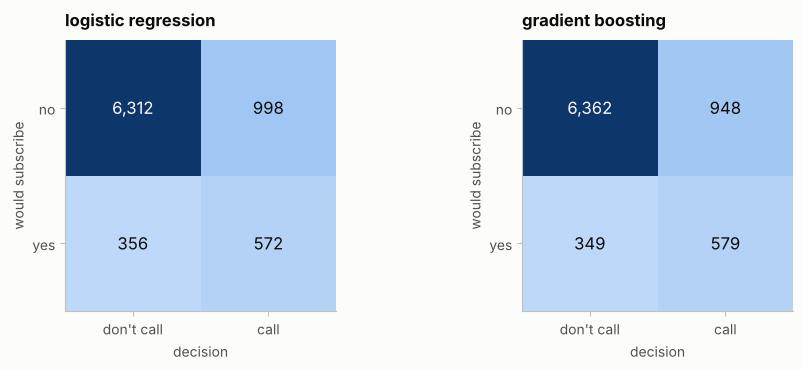

,AUC,AP,Brier,calls,precision,recall,profit
logistic regression,0.793,0.444,0.079,1570.0,0.364,0.616,15030.0
gradient boosting,0.801,0.461,0.077,1527.0,0.379,0.624,15525.0
call everyone,NaN,NaN,NaN,8238.0,0.113,1.000,-4070.0


In [15]:
from sklearn.metrics import confusion_matrix

test_probs = {name: model.fit(X_dev, y_dev).predict_proba(X_test)[:, 1] for name, model in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, (name, p) in zip(axes, test_probs.items()):
    cm = confusion_matrix(y_test, p >= break_even)
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                    color=SURFACE if cm[i, j] > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1], ["don't call", "call"])
    ax.set_yticks([0, 1], ["no", "yes"])
    ax.set_xlabel("decision")
    ax.set_ylabel("would subscribe")
    ax.set_title(name)
fig.tight_layout()
plt.show()

rows = {}
for name, p in test_probs.items():
    call = p >= break_even
    rows[name] = {"AUC": roc_auc_score(y_test, p), "AP": average_precision_score(y_test, p),
                  "Brier": brier_score_loss(y_test, p), "calls": int(call.sum()),
                  "precision": precision_score(y_test, call), "recall": recall_score(y_test, call),
                  "profit": profit(y_test, call)}
rows["call everyone"] = {"calls": len(y_test), "precision": y_test.mean(), "recall": 1.0,
                         "profit": profit(y_test, np.ones(len(y_test)))}
pd.DataFrame(rows).T.round(3)

On the test set, the numbers match cross-validation closely: AUCs around 0.8, well-calibrated probabilities (Brier scores below the baseline of about 0.10), and both models turn a loss into a profit. Calling about one customer in five, they reach around 60% of the subscribers, with more than a third of calls succeeding instead of one in nine.

### How sure are we?

Two questions need intervals. First, how much profit should the bank expect from the chosen model? Second, is gradient boosting really better than logistic regression, or is the gap luck? A paired bootstrap answers both, resampling the test customers and scoring both models on each resample:

In [16]:
rng = np.random.default_rng(0)
p_lr, p_gb = test_probs["logistic regression"], test_probs["gradient boosting"]
profits_gb, auc_differences, profit_differences = [], [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    yb = y_test[idx]
    profits_gb.append(profit(yb, p_gb[idx] >= break_even))
    profit_differences.append(profit(yb, p_gb[idx] >= break_even) - profit(yb, p_lr[idx] >= break_even))
    auc_differences.append(roc_auc_score(yb, p_gb[idx]) - roc_auc_score(yb, p_lr[idx]))

for label, values, fmt in [("gradient boosting profit", profits_gb, ",.0f"), ("profit: boosting - logistic", profit_differences, ",.0f"),
                           ("AUC: boosting - logistic", auc_differences, ".4f")]:
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"{label:<28} 95% interval {low:>8{fmt}} to {high:>8{fmt}}   above 0 in {np.mean(np.array(values) > 0):.0%} of resamples")

gradient boosting profit     95% interval   13,835 to   17,235   above 0 in 100% of resamples
profit: boosting - logistic  95% interval      -50 to      995   above 0 in 96% of resamples
AUC: boosting - logistic     95% interval  -0.0001 to   0.0168   above 0 in 97% of resamples


How to read these:

- **The profit is clearly positive.** The interval for gradient boosting's profit on 8,238 test customers is well above 0, so the model's value doesn't depend on a lucky test set.
- **The model comparison is not conclusive.** Boosting is ahead in most resamples, but the intervals for the differences reach 0 or slightly below it. On this evidence, the two models are about equally good, with a small edge to boosting.

When two models perform about the same, other things decide: logistic regression is simpler, faster, and its weights can be read and explained to the bank's compliance team. Gradient boosting may be slightly more profitable. Either is a defensible choice, and being honest that the difference is small is more useful to the bank than declaring a winner.

### Break the results down

An average can hide groups the model handles differently. Here's the boosting model's decision rule by age group:

In [17]:
age_group = pd.cut(X_test["age"], bins=[0, 29, 59, 120], labels=["under 30", "30 to 59", "60 and over"])
call = p_gb >= break_even
breakdown = pd.DataFrame({"group": age_group, "y": y_test, "call": call}).groupby("group", observed=True).apply(
    lambda g: pd.Series({"customers": len(g), "subscription rate": g["y"].mean(), "share called": g["call"].mean(),
                         "precision": g.loc[g["call"], "y"].mean(), "recall": g.loc[g["y"] == 1, "call"].mean()}),
    include_groups=False)
breakdown.round(3)

,customers,subscription rate,share called,precision,recall
group,,,,,
under 30,1153.0,0.160,0.294,0.381,0.701
30 to 59,6829.0,0.095,0.143,0.361,0.545
60 and over,256.0,0.383,0.836,0.458,1.000


The groups behave very differently. Customers aged 60 and over subscribe far more often than average, and the model calls most of them, with the highest precision of the three groups (though with only a few hundred of them in the test set, their numbers are noisy). The large middle group has the lowest base rate, so the model calls a much smaller share of it and finds a smaller share of its subscribers.

Is this a problem? Here the model is doing what it should: calling people more likely to want the product. But the same breakdown matters a great deal in other settings, such as credit, hiring or health, where treating age groups differently can be unfair or illegal. Module 21 looks at fairness properly. The habit to build now is to look.

## 7. Does it work on the future?

Everything so far used a random split. The test customers came from the same months as the training customers, so the test asks: "how well does the model rank customers from the same period as its training data?"

But the bank would use the model on **future** campaigns. To test that honestly, train only on the past and evaluate on what came later. Let's train on everything up to May 2009, the end of the busy period, and test on the calls from June 2009 onwards:

In [18]:
past = (bank["period"] <= "2009-05").to_numpy()
future = ~past
print(f"past:   {past.sum():>6,} calls, {y[past].mean():.1%} subscribed")
print(f"future: {future.sum():>6,} calls, {y[future].mean():.1%} subscribed")

rows = {}
for name, model in [("logistic regression", make_logistic()), ("gradient boosting", make_boosting())]:
    p = model.fit(X[past], y[past]).predict_proba(X[future])[:, 1]
    call = p >= break_even
    rows[name] = {"AUC": roc_auc_score(y[future], p), "average prediction": p.mean(),
                  "share called": call.mean(), "precision": y[future][call].mean(), "profit": profit(y[future], call)}
rows["call everyone"] = {"share called": 1.0, "precision": y[future].mean(), "profit": profit(y[future], np.ones(future.sum()))}
print(f"actual subscription rate in the future: {y[future].mean():.3f}")
pd.DataFrame(rows).T.round(3)

past:   36,224 calls, 6.7% subscribed
future:  4,964 calls, 44.5% subscribed


actual subscription rate in the future: 0.445


,AUC,average prediction,share called,precision,profit
logistic regression,0.630,0.394,0.943,0.455,61870.0
gradient boosting,0.601,0.176,0.489,0.528,39115.0
call everyone,NaN,NaN,1.000,0.445,63540.0


This is a sobering result, and the most important one in the project.

- **The ranking is much weaker.** The AUC drops from about 0.80 to around 0.6. The patterns that identified good prospects in 2008 to early 2009 only partly carry over to the later calls.
- **The probabilities are wrong.** In the future, about 45% of calls succeeded. Gradient boosting's average prediction is far below that: trees can't extrapolate, and the economic indicators in the future (interest rates below 1%) lie outside anything they saw in training, so they treat the new months like the most similar old ones. Logistic regression extrapolates the trend in the indicators and gets closer, but that's partly luck: a straight line happened to point the right way.
- **The decision rule no longer helps.** With 45% of calls succeeding, almost every call is profitable, and calling **everyone** on the future list earns more than following either model. Logistic regression gets close to that only because it ends up calling almost everyone; gradient boosting, with its too-low probabilities, skips half the list and leaves a lot of profit behind.

What would a careful team do with this?

1. **Report both numbers.** "AUC 0.80 on customers like the training data; around 0.6 on later campaigns" is honest. Reporting only the random-split number would promise far more than the model can deliver.
2. **Retrain often**, on recent data, and give recent months more weight.
3. **Monitor in production.** Track the actual success rate of the calls the model recommends, and compare it with the predicted probabilities. When they drift apart, as they would have here from mid-2009, recalibrate or retrain.
4. **Think about why the world changed.** If the bank's later calls were already chosen by some selection rule, the later data shows only customers that rule picked, and a model trained on it learns about that group, not about all customers. This problem of data shaped by earlier decisions is common in marketing, lending and medicine, and it's hard to fix after the fact.

## What we learned

- **Leakage can make a useless model look excellent.** `duration` raised the AUC from about 0.8 to about 0.93, and would have made the model worthless in practice. Always ask what's known at the moment of prediction.
- **Accuracy was meaningless** here: the models beat "always no" by about one point. Ranking metrics and the gains chart showed their real value: calling the top 20% reaches over 60% of subscribers.
- **Calibration** made the profit rule work: the break-even probability from the costs was the best threshold. **Class weighting** kept the ranking and destroyed the probabilities.
- **Decisions come from costs**, not from 0.5: with a call costing 5 and a subscription worth 40, the rule is to call when the probability is at least 0.125.
- **Intervals** showed the profit is real but the difference between the two models is small and uncertain.
- **The future is the real test.** A model evaluated on a random split of time-ordered data is evaluated on an easier problem than the one it will face. Here the ranking quality fell sharply and the profit rule stopped beating the simplest alternative.

### Ideas to go further

1. Rerun section 5 with different costs and values. At what value per subscription does calling everyone become the best choice?
2. Recalibrate the past-trained models on the most recent few months of the past (March to May 2009), using `CalibratedClassifierCV` with `cv="prefit"` or by fitting Platt scaling yourself (Exercise 11). Does the future calibration improve?
3. Try a **rolling evaluation**: for each month from 2009 onwards, train on everything before it and test on that month. Plot the AUC month by month.
4. Remove the five economic indicators and repeat sections 3 and 7. How much of the random-split AUC came from knowing **when** a call was made?
5. Add the `duration` leak back and look at which customers its "predictions" get right. Why is it so convincing?

Data: Moro, S., Rita, P., and Cortez, P. (2014). Bank Marketing. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306, licensed under CC BY 4.0. Described in: Moro, S., Cortez, P., and Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22-31.